# CS16 — Phase 3: Reproducible 3D CT Preprocessing and Patch QA

**Research objective:** prepare an audited 10-organ TotalSegmentator CT subset for lightweight,
uncertainty-aware multi-organ segmentation and patient-specific digital-twin reconstruction.

This notebook is a **data-preparation validation artifact**, not a model-performance experiment.
It demonstrates the complete path from audited NIfTI files to an exclusive 11-class label map,
calibrated CT normalization, deterministic 3D patches, and qualitative overlays.

> **Leakage guardrail:** only predeclared `train` cases are used. The locked 89-case test split is
> rejected before any test path can be resolved. No training, test evaluation, or dataset mutation
> occurs here.


## What this notebook must prove

1. The immutable manifest and organ-schema fingerprints still match.
2. Thirteen source masks are merged sequentially into ten exclusive foreground classes plus background.
3. Lung lobes are unioned first; cross-organ conflicts follow the declared TotalSegmentator v2
   last-label-wins priority.
4. Orientation and 1.5 mm spacing are verified, with CT/label interpolation rules kept explicit.
5. HU values are clipped to `[-1000, 1000]` and mapped to a fixed `[0, 1]` scale.
6. A deterministic `96³` class-balanced sampler works for both foreground and background-only scans.
7. Every acceptance check passes before model development begins.

The reusable implementation lives in `src/dataset/loader.py` and
`src/dataset/preprocessing.py`; this notebook calls those modules instead of duplicating them.


In [1]:
from __future__ import annotations

import json
import os
import platform
import sys
import time
from dataclasses import asdict
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import yaml
from IPython.display import Markdown, display
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

# Work both from the repository root and from a notebooks/ directory.
PROJECT_ROOT = next(
    candidate.resolve()
    for candidate in (Path.cwd(), Path.cwd().parent)
    if (candidate / "configs" / "dataset.yaml").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset import (
    canonicalize_to_ras,
    crop_pair,
    ct_foreground_bbox,
    development_cases,
    get_development_case,
    load_exclusive_case,
    load_organ_schema,
    load_preprocessing_spec,
    load_validated_manifest,
    normalize_ct,
    resample_pair,
    sample_class_balanced_patch,
)
from src.dataset.loader import resolve_dataset_path

DATASET_ROOT = Path(
    os.environ.get("TOTALSEG_DATASET_ROOT", PROJECT_ROOT / "Totalsegmentator_dataset_v201")
).resolve()
MANIFEST_PATH = PROJECT_ROOT / "data" / "splits" / "dataset_manifest.json"
ORGAN_CONFIG_PATH = PROJECT_ROOT / "configs" / "organs_v1.yaml"
DATASET_CONFIG_PATH = PROJECT_ROOT / "configs" / "dataset.yaml"
SELECTED_AUDIT_PATH = PROJECT_ROOT / "outputs" / "selected_organs_audit.csv"
DATASET_SUMMARY_PATH = PROJECT_ROOT / "outputs" / "dataset_summary.json"
ORGAN_SUMMARY_PATH = PROJECT_ROOT / "outputs" / "organ_volume_statistics.json"
PHASE3_OUTPUT = PROJECT_ROOT / "outputs" / "phase3"
PHASE3_OUTPUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "font.size": 9})
np.set_printoptions(precision=4, suppress=True)

runtime = pd.DataFrame(
    [
        ("Python", platform.python_version()),
        ("NumPy", np.__version__),
        ("SciPy", scipy.__version__),
        ("Pandas", pd.__version__),
        ("Matplotlib", matplotlib.__version__),
        ("Platform", platform.platform()),
    ],
    columns=["Component", "Version"],
)
display(runtime.style.hide(axis="index"))
print(f"Project root : {PROJECT_ROOT}")
print(f"Dataset root : {DATASET_ROOT}")


Component,Version
Python,3.13.12
NumPy,2.5.2
SciPy,1.18.0
Pandas,3.0.5
Matplotlib,3.11.1
Platform,Windows-11-10.0.26200-SP0


Project root : F:\csstdy
Dataset root : F:\csstdy\Totalsegmentator_dataset_v201


## 1. Load the immutable data contract

The official `meta.csv` split is preserved: 1,082 train, 57 validation, and 89 locked test
cases. The notebook validates the stored manifest hash, schema hash, test lock, case uniqueness,
and split counts before loading a voxel.


In [2]:
schema = load_organ_schema(ORGAN_CONFIG_PATH)
spec = load_preprocessing_spec(DATASET_CONFIG_PATH)
manifest = load_validated_manifest(MANIFEST_PATH, schema)
dataset_summary = json.loads(DATASET_SUMMARY_PATH.read_text(encoding="utf-8"))
organ_summary = json.loads(ORGAN_SUMMARY_PATH.read_text(encoding="utf-8"))

preprocessing_sha256 = spec.fingerprint(
    manifest_sha256=manifest["manifest_sha256"],
    schema_sha256=schema.fingerprint(),
)
assert manifest["split_policy"]["test_lock"]["locked"] is True
assert organ_summary["all_integrity_checks_passed"] is True
assert schema.num_output_channels == 11

audit_evidence = pd.DataFrame(
    [
        ("Cases", dataset_summary["subject_count"]),
        ("CT payloads fully CRC-checked", dataset_summary["valid_ct_payload_count"]),
        ("Selected source masks fully CRC-checked", organ_summary["source_crc_checked_count"]),
        ("Selected-mask integrity errors", organ_summary["severity_counts"].get("error", 0)),
        ("Resolved overlap warnings", organ_summary["severity_counts"].get("warning", 0)),
        ("Development scans with no selected foreground", organ_summary["development_cases_with_no_selected_foreground"]),
        ("Train / val / locked test", "1082 / 57 / 89"),
        ("Orientation / nominal spacing", "RAS / 1.5 mm isotropic"),
    ],
    columns=["Audit evidence", "Result"],
)
display(audit_evidence.style.hide(axis="index"))
print("Manifest SHA-256     :", manifest["manifest_sha256"])
print("Organ schema SHA-256 :", schema.fingerprint())
print("Preprocessing SHA-256:", preprocessing_sha256)


Audit evidence,Result
Cases,1228
CT payloads fully CRC-checked,1228
Selected source masks fully CRC-checked,15964
Selected-mask integrity errors,0
Resolved overlap warnings,664
Development scans with no selected foreground,78
Train / val / locked test,1082 / 57 / 89
Orientation / nominal spacing,RAS / 1.5 mm isotropic


Manifest SHA-256     : 4c94df936370ee913b0202fc5a34cba9843727d8dabb0552a3b8160dea223d8d
Organ schema SHA-256 : 082fa87535d1a4c91d0eaf4aa074ebf297cd0ec386183643038bf2c583989c05
Preprocessing SHA-256: 92ec417172ae9a564135fed9bb0ae173de5305651f96220c57b29655e92b8c71


## 2. Output channels and overlap policy

Numeric class IDs define model channels. Conflict priority is a separate order and must not be
inferred from those IDs. The loader first unions each lung's lobe masks, then assigns targets in
the configured low-to-high priority; later targets overwrite earlier ones.


In [3]:
mapping_rows = [{"class_id": 0, "target": "background", "source_masks": "—"}]
mapping_rows.extend(
    {
        "class_id": label.id,
        "target": label.name,
        "source_masks": " + ".join(label.source_masks),
    }
    for label in schema.labels
)
display(pd.DataFrame(mapping_rows).style.hide(axis="index"))
display(Markdown("**Conflict priority (low → high):**  " + " → ".join(schema.overlap_priority)))
print("Policy:", schema.overlap_method)
print("Official reference:", schema.overlap_reference)


class_id,target,source_masks
0,background,—
1,liver,liver
2,spleen,spleen
3,kidney_left,kidney_left
4,kidney_right,kidney_right
5,stomach,stomach
6,pancreas,pancreas
7,aorta,aorta
8,inferior_vena_cava,inferior_vena_cava
9,lung_left,lung_upper_lobe_left + lung_lower_lobe_left


**Conflict priority (low → high):**  spleen → kidney_right → kidney_left → liver → stomach → pancreas → lung_left → lung_right → aorta → inferior_vena_cava

Policy: official_totalsegmentator_v2_last_label_wins
Official reference: https://github.com/wasserth/TotalSegmentator/blob/master/totalsegmentator/libs.py


## 3. Freeze qualitative QA cases before model training

Case selection is declared now so later predictions cannot influence the examples shown in a paper.

- `s0014` (train): all ten organs and 15,561 genuine cross-target conflict voxels; exercises priority.
- `s0099` (train): no selected-organ foreground and one dimension below 96; exercises fallback/padding.


In [4]:
PRIMARY_CASE_ID = "s0014"
BACKGROUND_CASE_ID = "s0099"
primary_record = get_development_case(manifest, PRIMARY_CASE_ID)
background_record = get_development_case(manifest, BACKGROUND_CASE_ID)
assert primary_record["split"] == background_record["split"] == "train"

case_contract = pd.DataFrame(
    [
        {
            "case_id": PRIMARY_CASE_ID,
            "split": primary_record["split"],
            "shape": "×".join(map(str, primary_record["ct"]["shape"])),
            "purpose": "all classes + overlap-resolution regression",
        },
        {
            "case_id": BACKGROUND_CASE_ID,
            "split": background_record["split"],
            "shape": "×".join(map(str, background_record["ct"]["shape"])),
            "purpose": "background-only fallback + ROI padding",
        },
    ]
)
display(case_contract.style.hide(axis="index"))

def manifest_case_paths(case_record):
    paths = [resolve_dataset_path(DATASET_ROOT, case_record["ct"]["path"])]
    for target in case_record["targets"].values():
        paths.extend(resolve_dataset_path(DATASET_ROOT, source["path"]) for source in target["sources"])
    return paths

observed_source_paths = manifest_case_paths(primary_record) + manifest_case_paths(background_record)
source_snapshot_before = {
    str(path): (path.stat().st_size, path.stat().st_mtime_ns) for path in observed_source_paths
}
print(f"Read-only source files tracked: {len(observed_source_paths)}")


case_id,split,shape,purpose
s0014,train,286×286×308,all classes + overlap-resolution regression
s0099,train,108×108×77,background-only fallback + ROI padding


Read-only source files tracked: 28


## 4. Build the native exclusive label map

Peak memory is bounded: the float32 CT and uint8 output label remain resident, while each binary
source mask is read, CRC-checked, merged, and released sequentially. The exclusive map is built
**before** any spatial interpolation so resampling cannot create new overlaps.


In [5]:
started = time.perf_counter()
primary = load_exclusive_case(DATASET_ROOT, primary_record, schema)
load_seconds = time.perf_counter() - started

selected_audit = pd.read_csv(SELECTED_AUDIT_PATH)
expected_rows = selected_audit.loc[selected_audit["case_id"].eq(PRIMARY_CASE_ID)].set_index("organ")
count_rows = []
for label_definition in schema.labels:
    name = label_definition.name
    expected_raw = int(expected_rows.loc[name, "foreground_voxels"])
    expected_exclusive = int(expected_rows.loc[name, "exclusive_foreground_voxels"])
    actual_raw = primary.raw_foreground_voxels[name]
    actual_exclusive = primary.exclusive_foreground_voxels[name]
    count_rows.append(
        {
            "id": label_definition.id,
            "organ": name,
            "raw voxels": actual_raw,
            "exclusive voxels": actual_exclusive,
            "removed by priority": actual_raw - actual_exclusive,
            "matches prior audit": actual_raw == expected_raw and actual_exclusive == expected_exclusive,
        }
    )
count_table = pd.DataFrame(count_rows)
assert count_table["matches prior audit"].all()
assert primary.source_masks_checked == 13
assert primary.cross_target_conflict_voxels == 15_561

display(count_table.style.hide(axis="index").format({"raw voxels": "{:,}", "exclusive voxels": "{:,}", "removed by priority": "{:,}"}))
print(f"Loaded {primary.case_id} in {load_seconds:.2f} s")
print("CT shape/dtype      :", primary.ct_hu.shape, primary.ct_hu.dtype)
print("Label shape/dtype   :", primary.label.shape, primary.label.dtype)
print("Source masks checked:", primary.source_masks_checked)
print("Conflict voxels     :", primary.cross_target_conflict_voxels)


id,organ,raw voxels,exclusive voxels,removed by priority,matches prior audit
1,liver,"433,494","418,207","15,287",True
2,spleen,"85,994","85,994",0,True
3,kidney_left,"55,780","55,780",0,True
4,kidney_right,"53,721","53,721",0,True
5,stomach,"941,172","940,898",274,True
6,pancreas,"20,262","20,262",0,True
7,aorta,"29,771","29,771",0,True
8,inferior_vena_cava,"21,099","21,099",0,True
9,lung_left,"97,408","97,408",0,True
10,lung_right,"129,225","129,225",0,True


Loaded s0014 in 3.32 s
CT shape/dtype      : (286, 286, 308) float32
Label shape/dtype   : (286, 286, 308) uint8
Source masks checked: 13
Conflict voxels     : 15561


## 5. Spatial and intensity preprocessing

The audited release is already RAS and 1.5 mm isotropic, so both spatial operations should be exact
no-ops for this case. The functions still record the transform and specify linear interpolation for CT
and nearest-neighbour interpolation for labels when a future scan genuinely needs resampling.

NIfTI spatial-unit flags are unset in this release; millimetres are the explicit project fallback,
justified by the audited uniform 1.5 spacing and affines.


In [6]:
ras_hu, ras_label, ras_affine, orientation_trace = canonicalize_to_ras(
    primary.ct_hu, primary.label, primary.affine
)
spatial_hu, spatial_label, spatial_affine, resample_trace = resample_pair(
    ras_hu,
    ras_label,
    ras_affine,
    spec.spacing_mm,
    image_fill_hu=spec.hu_lower,
)
normalized = normalize_ct(spatial_hu, spec)

assert orientation_trace["target_orientation"] == "RAS"
assert orientation_trace["was_noop"] and resample_trace["was_noop"]
assert np.array_equal(spatial_label, primary.label)
assert normalized.dtype == np.float32 and np.isfinite(normalized).all()
assert float(normalized.min()) >= spec.normalized_lower
assert float(normalized.max()) <= spec.normalized_upper

spatial_table = pd.DataFrame(
    [
        ("Orientation", orientation_trace["source_orientation"], orientation_trace["target_orientation"], orientation_trace["was_noop"]),
        ("Spacing (mm)", tuple(round(v, 5) for v in resample_trace["source_spacing_mm"]), tuple(spec.spacing_mm), resample_trace["was_noop"]),
        ("Shape", tuple(primary.ct_hu.shape), tuple(spatial_hu.shape), tuple(primary.ct_hu.shape) == tuple(spatial_hu.shape)),
        ("Label IDs", sorted(np.unique(primary.label).tolist()), sorted(np.unique(spatial_label).tolist()), np.array_equal(primary.label, spatial_label)),
    ],
    columns=["Check", "Before", "After", "Exact/no-op"],
)
display(spatial_table.style.hide(axis="index"))
print(f"HU input range       : {primary.ct_hu.min():.1f} to {primary.ct_hu.max():.1f}")
print(f"Normalized range     : {normalized.min():.3f} to {normalized.max():.3f}")
print(f"Configured HU window : [{spec.hu_lower:.0f}, {spec.hu_upper:.0f}]")


Check,Before,After,Exact/no-op
Orientation,RAS,RAS,True
Spacing (mm),"(1.5, 1.5, 1.5)","(1.5, 1.5, 1.5)",True
Shape,"(286, 286, 308)","(286, 286, 308)",True
Label IDs,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",True


HU input range       : -1298.0 to 2663.0
Normalized range     : 0.000 to 1.000
Configured HU window : [-1000, 1000]


## 6. Three-plane anatomical overlay

Slice positions are algorithmic—not hand-picked. For each anatomical plane, the notebook selects the
slice with the largest total selected-organ area and records its index.


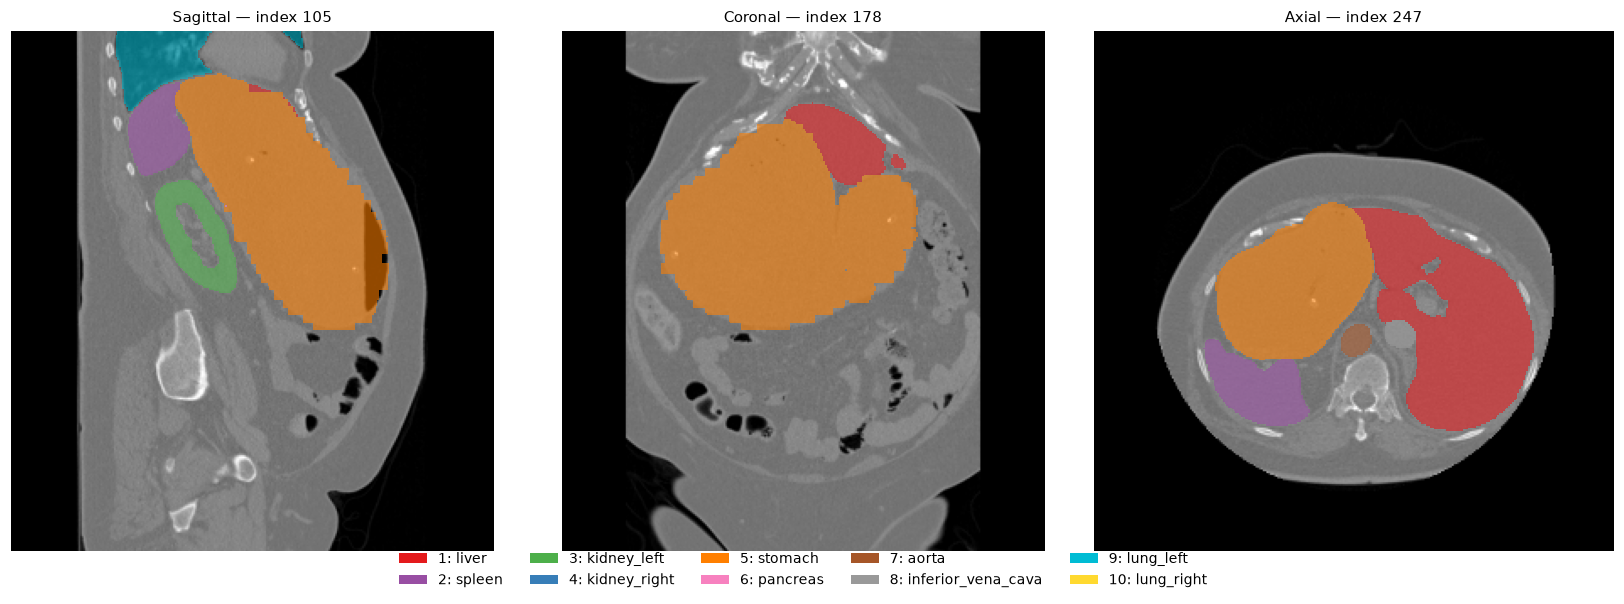

Saved: F:\csstdy\outputs\phase3\s0014_multiplanar_overlay.png
Recorded slice indices: {'Sagittal': 105, 'Coronal': 178, 'Axial': 247}


In [7]:
organ_colors = [
    "#00000000", "#e41a1c", "#984ea3", "#4daf4a", "#377eb8", "#ff7f00",
    "#f781bf", "#a65628", "#999999", "#00bcd4", "#ffd92f",
]
label_cmap = ListedColormap(organ_colors)
label_norm = BoundaryNorm(np.arange(-0.5, 11.5, 1), label_cmap.N)
class_name = {0: "background", **{item.id: item.name for item in schema.labels}}

def best_slice(label_volume, axis):
    other_axes = tuple(index for index in range(3) if index != axis)
    return int(np.argmax(np.count_nonzero(label_volume, axis=other_axes)))

def plane(volume, axis, index):
    return np.take(volume, index, axis=axis).T

plane_names = {0: "Sagittal", 1: "Coronal", 2: "Axial"}
slice_indices = {axis: best_slice(spatial_label, axis) for axis in range(3)}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
for axis, ax in enumerate(axes):
    index = slice_indices[axis]
    ct_slice = plane(spatial_hu, axis, index)
    seg_slice = plane(spatial_label, axis, index)
    ax.imshow(ct_slice, cmap="gray", vmin=spec.hu_lower, vmax=spec.hu_upper, origin="lower")
    ax.imshow(np.ma.masked_equal(seg_slice, 0), cmap=label_cmap, norm=label_norm, alpha=0.58, origin="lower", interpolation="nearest")
    ax.set_title(f"{plane_names[axis]} — index {index}")
    ax.axis("off")
handles = [Patch(facecolor=organ_colors[item.id], label=f"{item.id}: {item.name}") for item in schema.labels]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.08))
figure_path = PHASE3_OUTPUT / "s0014_multiplanar_overlay.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", figure_path)
print("Recorded slice indices:", {plane_names[k]: v for k, v in slice_indices.items()})


## 7. Deterministic class-balanced 3D patch

Present foreground classes are sampled uniformly so large organs do not dominate only because they
contain more voxels. The center is then sampled uniformly within the chosen class. Ten percent of
samples use a CT-derived body/background center. Seed derivation combines the project seed, case ID,
and sample index, making every patch exactly reproducible.


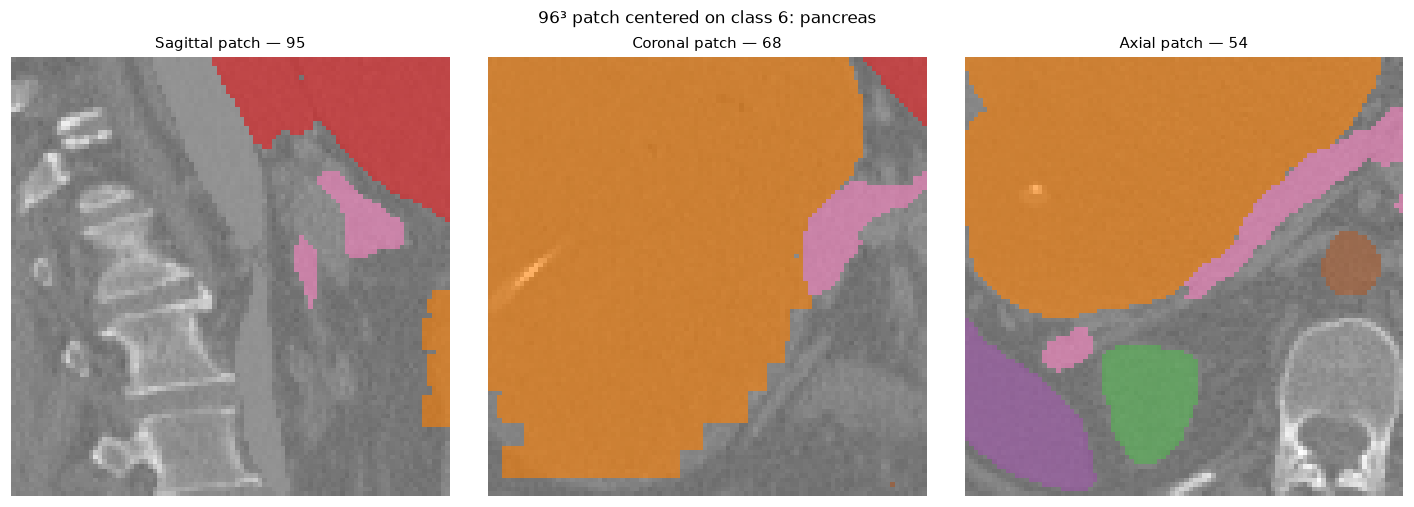

case_id,sample_index,mode,selected_class_id,center,requested_start,source_start,source_end,padding_before,padding_after,derived_seed
s0014,14,foreground_class_balanced,6,"(118, 127, 208)","(70, 79, 160)","(70, 79, 160)","(166, 175, 256)","(0, 0, 0)","(0, 0, 0)",16113329376083968643


Saved: F:\csstdy\outputs\phase3\s0014_class_balanced_patch.png


In [8]:
SAMPLE_INDEX = 14  # frozen before training; deterministically selects pancreas in s0014
image_patch, label_patch, patch_trace = sample_class_balanced_patch(
    normalized,
    spatial_label,
    spatial_hu,
    spec,
    case_id=PRIMARY_CASE_ID,
    sample_index=SAMPLE_INDEX,
)
repeat_image, repeat_label, repeat_trace = sample_class_balanced_patch(
    normalized,
    spatial_label,
    spatial_hu,
    spec,
    case_id=PRIMARY_CASE_ID,
    sample_index=SAMPLE_INDEX,
)
patch_reproducible = (
    np.array_equal(image_patch, repeat_image)
    and np.array_equal(label_patch, repeat_label)
    and patch_trace == repeat_trace
)
assert patch_reproducible
assert patch_trace.mode == "foreground_class_balanced"
assert patch_trace.selected_class_id in np.unique(label_patch)
assert image_patch.shape == (1, *spec.roi_size) and label_patch.shape == spec.roi_size

patch_indices = {axis: best_slice(label_patch == patch_trace.selected_class_id, axis) for axis in range(3)}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), constrained_layout=True)
for axis, ax in enumerate(axes):
    index = patch_indices[axis]
    ax.imshow(plane(image_patch[0], axis, index), cmap="gray", vmin=0, vmax=1, origin="lower")
    ax.imshow(np.ma.masked_equal(plane(label_patch, axis, index), 0), cmap=label_cmap, norm=label_norm, alpha=0.6, origin="lower", interpolation="nearest")
    ax.set_title(f"{plane_names[axis]} patch — {index}")
    ax.axis("off")
fig.suptitle(f"96³ patch centered on class {patch_trace.selected_class_id}: {class_name[patch_trace.selected_class_id]}")
patch_path = PHASE3_OUTPUT / "s0014_class_balanced_patch.png"
fig.savefig(patch_path, dpi=180, bbox_inches="tight")
plt.show()
display(pd.DataFrame([asdict(patch_trace)]).style.hide(axis="index"))
print("Saved:", patch_path)


## 8. Background-only scans are retained

Partial-field scans with no selected organ are valid observations, not corrupt cases. `s0099` proves
that the sampler returns a deterministic body/background patch and pads dimensions smaller than 96,
instead of silently dropping the patient or crashing.


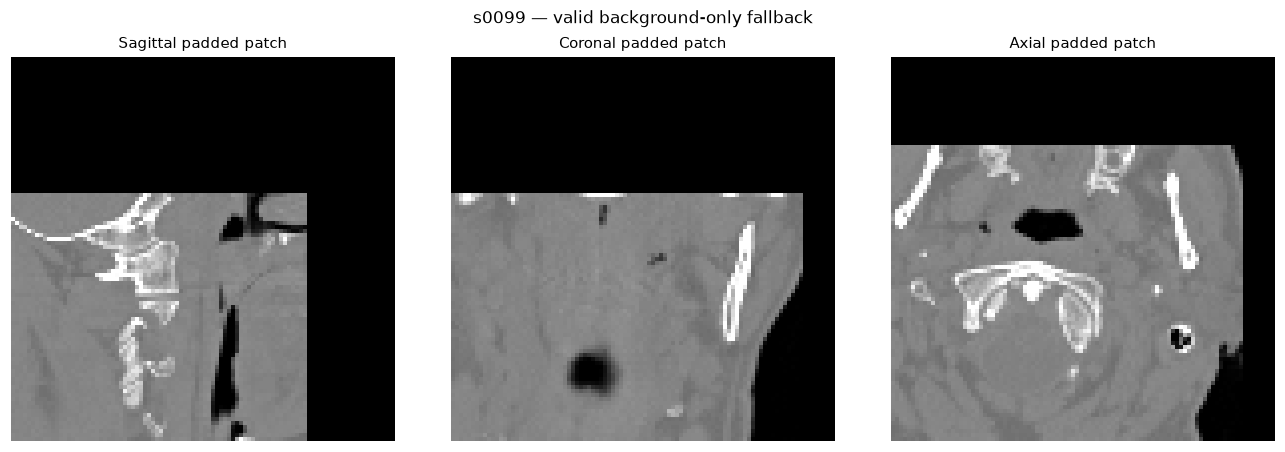

case_id,sample_index,mode,selected_class_id,center,requested_start,source_start,source_end,padding_before,padding_after,derived_seed
s0099,0,background_only_fallback,0,"(68, 82, 63)","(20, 34, 15)","(20, 34, 15)","(108, 108, 77)","(0, 0, 0)","(8, 22, 34)",971702286858572692


Saved: F:\csstdy\outputs\phase3\s0099_background_fallback_patch.png


In [9]:
background = load_exclusive_case(DATASET_ROOT, background_record, schema)
assert np.array_equal(np.unique(background.label), np.asarray([0], dtype=np.uint8))
background_normalized = normalize_ct(background.ct_hu, spec)
background_patch, background_label_patch, background_trace = sample_class_balanced_patch(
    background_normalized,
    background.label,
    background.ct_hu,
    spec,
    case_id=BACKGROUND_CASE_ID,
    sample_index=0,
)
bg_repeat_image, bg_repeat_label, bg_repeat_trace = sample_class_balanced_patch(
    background_normalized,
    background.label,
    background.ct_hu,
    spec,
    case_id=BACKGROUND_CASE_ID,
    sample_index=0,
)
background_reproducible = (
    np.array_equal(background_patch, bg_repeat_image)
    and np.array_equal(background_label_patch, bg_repeat_label)
    and background_trace == bg_repeat_trace
)
assert background_trace.mode == "background_only_fallback"
assert background_reproducible and not np.any(background_label_patch)
assert any(background_trace.padding_before) or any(background_trace.padding_after)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for axis, ax in enumerate(axes):
    index = spec.roi_size[axis] // 2
    ax.imshow(plane(background_patch[0], axis, index), cmap="gray", vmin=0, vmax=1, origin="lower")
    ax.set_title(f"{plane_names[axis]} padded patch")
    ax.axis("off")
fig.suptitle("s0099 — valid background-only fallback")
background_path = PHASE3_OUTPUT / "s0099_background_fallback_patch.png"
fig.savefig(background_path, dpi=180, bbox_inches="tight")
plt.show()
display(pd.DataFrame([asdict(background_trace)]).style.hide(axis="index"))
print("Saved:", background_path)


## 9. CT-derived foreground cropping: implemented, evaluated, not globally enabled

Cropping must be reproducible at inference, so the box is derived only from CT intensity—not from the
ground-truth organ label. The current `-900 HU` / 10-voxel-margin candidate reduces this case while
retaining its selected labels, but remains disabled in `dataset.yaml` until retention is checked over
every training and validation case.


In [10]:
crop_bbox = ct_foreground_bbox(
    spatial_hu,
    threshold_hu=spec.foreground_crop_threshold_hu,
    margin_voxels=spec.foreground_crop_margin_voxels,
)
cropped_hu, cropped_label, cropped_affine = crop_pair(
    spatial_hu, spatial_label, spatial_affine, crop_bbox
)
crop_retention = np.count_nonzero(cropped_label) / max(1, np.count_nonzero(spatial_label))
crop_reduction = 1.0 - cropped_hu.size / spatial_hu.size
crop_table = pd.DataFrame(
    [
        ("Configured globally", spec.foreground_crop_enabled),
        ("CT threshold", f"{spec.foreground_crop_threshold_hu:.0f} HU"),
        ("Bounding box", crop_bbox),
        ("Shape before", spatial_hu.shape),
        ("Shape after", cropped_hu.shape),
        ("Voxel reduction", f"{crop_reduction:.1%}"),
        ("Selected-label retention", f"{crop_retention:.1%}"),
    ],
    columns=["Crop check", "Result"],
)
display(crop_table.style.hide(axis="index"))
assert crop_retention == 1.0


Crop check,Result
Configured globally,False
CT threshold,-900 HU
Bounding box,"((22, 264), (24, 264), (0, 308))"
Shape before,"(286, 286, 308)"
Shape after,"(242, 240, 308)"
Voxel reduction,29.0%
Selected-label retention,100.0%


## 10. Acceptance matrix and machine-readable provenance

The cell below is the Phase 3 gate. It also writes a compact JSON record and presentation PNGs under
`outputs/phase3/`; original NIfTI files remain untouched.


In [11]:
try:
    development_cases(manifest, "test")
    test_lock_enforced = False
except PermissionError:
    test_lock_enforced = True

source_snapshot_after = {
    str(path): (path.stat().st_size, path.stat().st_mtime_ns) for path in observed_source_paths
}
source_files_unchanged = source_snapshot_before == source_snapshot_after

acceptance = {
    "manifest fingerprint valid": manifest["manifest_sha256"] == "4c94df936370ee913b0202fc5a34cba9843727d8dabb0552a3b8160dea223d8d",
    "organ schema fingerprint valid": schema.fingerprint() == "082fa87535d1a4c91d0eaf4aa074ebf297cd0ec386183643038bf2c583989c05",
    "locked test access rejected before path resolution": test_lock_enforced,
    "13 source masks loaded sequentially": primary.source_masks_checked == 13,
    "CT finite float32": primary.ct_hu.dtype == np.float32 and bool(np.isfinite(primary.ct_hu).all()),
    "exclusive label uint8 with ids 0–10": primary.label.dtype == np.uint8 and set(np.unique(primary.label)) <= set(range(11)),
    "exclusive counts exactly match prior full audit": bool(count_table["matches prior audit"].all()),
    "RAS conversion is exact no-op": orientation_trace["was_noop"] and np.array_equal(ras_label, primary.label),
    "1.5 mm resampling is exact no-op": resample_trace["was_noop"] and np.array_equal(spatial_label, primary.label),
    "fixed HU normalization finite and bounded": bool(np.isfinite(normalized).all()) and 0 <= float(normalized.min()) <= float(normalized.max()) <= 1,
    "foreground patch shape is image 1×96³ / label 96³": image_patch.shape == (1, 96, 96, 96) and label_patch.shape == (96, 96, 96),
    "foreground patch is exactly reproducible": patch_reproducible,
    "selected center class remains in foreground patch": patch_trace.selected_class_id in np.unique(label_patch),
    "background-only fallback succeeds with padding": background_trace.mode == "background_only_fallback" and any(background_trace.padding_after),
    "background-only patch is exactly reproducible": background_reproducible,
    "CT-only crop preview retains all selected labels": crop_retention == 1.0,
    "original dataset files unchanged": source_files_unchanged,
}
acceptance = {name: bool(passed) for name, passed in acceptance.items()}
acceptance_table = pd.DataFrame(
    [{"Acceptance check": name, "Status": "PASS" if passed else "FAIL"} for name, passed in acceptance.items()]
)
display(
    acceptance_table.style.hide(axis="index").map(
        lambda value: "color: #087f23; font-weight: bold" if value == "PASS" else ("color: #b00020; font-weight: bold" if value == "FAIL" else "")
    )
)
if not all(acceptance.values()):
    raise AssertionError("Phase 3 acceptance gate failed")

qa_summary = {
    "stage": "phase3_preprocessing_and_patch_qa",
    "status": "passed",
    "manifest_sha256": manifest["manifest_sha256"],
    "organ_schema_sha256": schema.fingerprint(),
    "preprocessing_sha256": preprocessing_sha256,
    "dataset_root_recorded_as": "TOTALSEG_DATASET_ROOT or project-relative Totalsegmentator_dataset_v201",
    "test_split_accessed": False,
    "primary_case": PRIMARY_CASE_ID,
    "background_only_case": BACKGROUND_CASE_ID,
    "primary_native_shape": list(primary.ct_hu.shape),
    "orientation_trace": orientation_trace,
    "resample_trace": resample_trace,
    "hu_window": [spec.hu_lower, spec.hu_upper],
    "normalized_range": [spec.normalized_lower, spec.normalized_upper],
    "roi_size": list(spec.roi_size),
    "primary_conflict_voxels": primary.cross_target_conflict_voxels,
    "primary_exclusive_counts": primary.exclusive_foreground_voxels,
    "foreground_patch_trace": asdict(patch_trace),
    "background_patch_trace": asdict(background_trace),
    "crop_preview": {
        "globally_enabled": spec.foreground_crop_enabled,
        "bbox": [list(item) for item in crop_bbox],
        "voxel_reduction_fraction": crop_reduction,
        "selected_label_retention_fraction": crop_retention,
    },
    "acceptance": acceptance,
    "limitations": [
        "No segmentation model is trained or evaluated in this notebook.",
        "The locked test split is not accessed.",
        "NIfTI spatial units are unset; millimetres are the audited project fallback.",
        "CT-derived foreground cropping remains disabled pending dataset-wide retention QA.",
        "The separately pinned CUDA PyTorch/MONAI environment is validated outside this CPU-safe notebook.",
    ],
}
qa_summary_path = PHASE3_OUTPUT / "qa_summary.json"
qa_summary_path.write_text(json.dumps(qa_summary, indent=2, allow_nan=False) + "\n", encoding="utf-8")
display(Markdown(f"### ✅ Phase 3 gate passed\n\nMachine-readable record: `{qa_summary_path.relative_to(PROJECT_ROOT)}`"))


Acceptance check,Status
manifest fingerprint valid,PASS
organ schema fingerprint valid,PASS
locked test access rejected before path resolution,PASS
13 source masks loaded sequentially,PASS
CT finite float32,PASS
exclusive label uint8 with ids 0–10,PASS
exclusive counts exactly match prior full audit,PASS
RAS conversion is exact no-op,PASS
1.5 mm resampling is exact no-op,PASS
fixed HU normalization finite and bounded,PASS


### ✅ Phase 3 gate passed

Machine-readable record: `outputs\phase3\qa_summary.json`

## MONAI-ready transform contract and next boundary

The validated operations map directly to the Phase 4 MONAI training stack:

| Validated operation | MONAI training equivalent | Rule |
|---|---|---|
| Manifest NIfTI load + exclusive merge | custom `MapTransform` before caching | merge on native grid; stream 13 masks |
| Canonical orientation | `Orientationd(axcodes="RAS")` | same transform for image and label |
| Common spacing | `Spacingd(pixdim=(1.5,1.5,1.5), mode=("bilinear","nearest"))` | never linearly interpolate labels |
| Fixed CT window | `ScaleIntensityRanged(-1000,1000,0,1,clip=True)` | preserve calibrated HU meaning |
| Class-balanced ROI | `RandCropByLabelClassesd(spatial_size=(96,96,96))` plus background-only fallback | deterministic worker/case seeds |

The separate GPU environment is now pinned in `requirements-gpu.txt` and validated with a real Phase 3
patch by `scripts/verify_gpu_stack.py`. Its machine-readable record is
`outputs/environment/gpu_verification.json`. This Phase 3 notebook remains CPU-safe and does not train a
model; paired augmentation and research-baseline training begin only in Phase 4.

Official references: [MONAI installation guide](https://github.com/Project-MONAI/MONAI/blob/dev/docs/source/installation.md),
[TotalSegmentator multilabel conversion](https://github.com/wasserth/TotalSegmentator/blob/master/totalsegmentator/libs.py).

**No Dice score or model-quality claim can be made from this notebook.** It establishes that the data
entering future 3D U-Net, nnU-Net v2, and Swin UNETR experiments are geometrically aligned,
leakage-safe, deterministic, and auditable.


## GPU environment verification appendix

This presentation-only appendix reads the already-generated validation record; it does not rerun CUDA,
touch the test split, augment the research dataset, or retain a trained model. The validation itself used
one real training patch for a disposable forward/backward optimizer smoke step.


In [12]:
GPU_REPORT_PATH = PROJECT_ROOT / "outputs" / "environment" / "gpu_verification.json"
gpu_report = json.loads(GPU_REPORT_PATH.read_text(encoding="utf-8"))

assert gpu_report["status"] == "passed"
assert gpu_report["all_checks_passed"] is True
assert gpu_report["test_split_accessed"] is False
assert gpu_report["test_lock_enforced"] is True

gpu_summary = pd.DataFrame(
    [
        ("Validation status", gpu_report["status"].upper()),
        ("Generated (UTC)", gpu_report["generated_at_utc"]),
        ("GPU", gpu_report["device"]["name"]),
        ("Compute capability", ".".join(map(str, gpu_report["device"]["compute_capability"]))),
        ("VRAM", f'{gpu_report["device"]["total_memory_mib"]:.0f} MiB'),
        ("NVIDIA driver", gpu_report["driver"]["nvidia_smi"]["output"].split(",")[2].strip()),
        ("PyTorch", gpu_report["environment"]["torch"]),
        ("PyTorch CUDA runtime", gpu_report["environment"]["pytorch_cuda_runtime"]),
        ("cuDNN", gpu_report["environment"]["cudnn_version_string"]),
        ("MONAI", gpu_report["environment"]["monai"]),
        ("NiBabel", gpu_report["environment"]["nibabel"]),
        ("Real smoke-test case", f'{gpu_report["provenance"]["real_case_id"]} ({gpu_report["provenance"]["real_case_split"]})'),
        ("Peak allocated VRAM", f'{gpu_report["checks"]["monai_real_patch_amp_training_step"]["peak_allocated_mib"]:.1f} MiB'),
        ("Locked test accessed", str(gpu_report["test_split_accessed"])),
    ],
    columns=["Field", "Verified value"],
)

check_names = {
    "cuda_allocation_and_reduction": "CUDA allocation + reduction",
    "cuda_matmul_cpu_parity": "CUDA matmul CPU parity",
    "cuda_conv3d_with_cudnn_enabled": "Conv3d forward/backward (cuDNN enabled)",
    "cuda_amp_grad_scaler_optimizer": "float16 AMP + GradScaler optimizer",
    "real_phase3_patch_to_cuda": "Real Phase 3 patch transfer",
    "monai_paired_cuda_transform": "Paired MONAI CUDA transform",
    "monai_real_patch_amp_training_step": "MONAI 3D U-Net disposable training step",
}
gpu_checks = pd.DataFrame(
    [
        {
            "Check": check_names[name],
            "Result": "PASS" if details["passed"] else "FAIL",
            "Elapsed (s)": details.get("elapsed_seconds"),
        }
        for name, details in gpu_report["checks"].items()
    ]
)

display(gpu_summary.style.hide(axis="index"))
display(gpu_checks.style.hide(axis="index").format({"Elapsed (s)": lambda value: "—" if pd.isna(value) else f"{value:.3f}"}))
display(
    Markdown(
        "**Interpretation:** all seven GPU checks passed on the real-data pipeline. "
        "This validates execution and compatibility, not segmentation accuracy.  \n"
        f'**Determinism limitation:** {gpu_report["environment"]["determinism_note"]}'
    )
)


Field,Verified value
Validation status,PASSED
Generated (UTC),2026-08-18T09:43:17.703855Z
GPU,NVIDIA GeForce RTX 4060 Laptop GPU
Compute capability,8.9
VRAM,8188 MiB
NVIDIA driver,592.82
PyTorch,2.13.0+cu130
PyTorch CUDA runtime,13.0
cuDNN,9.20.0
MONAI,1.6.0


Check,Result,Elapsed (s)
CUDA allocation + reduction,PASS,0.056
CUDA matmul CPU parity,PASS,0.314
Conv3d forward/backward (cuDNN enabled),PASS,0.393
float16 AMP + GradScaler optimizer,PASS,0.149
Real Phase 3 patch transfer,PASS,—
Paired MONAI CUDA transform,PASS,0.032
MONAI 3D U-Net disposable training step,PASS,0.892


**Interpretation:** all seven GPU checks passed on the real-data pipeline. This validates execution and compatibility, not segmentation accuracy.  
**Determinism limitation:** CUDA CrossEntropy for 5D segmentation is not marked strictly deterministic in this build.